**Shipment Delay Insight**

In [1]:
from google.colab import files

uploaded = files.upload()

Saving carriers.csv to carriers.csv
Saving events.csv to events.csv
Saving routes.csv to routes.csv
Saving shipments.csv to shipments.csv
Saving weather.csv to weather.csv


**1.Dataset Loading and Data Information**





In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all five datasets
shipments = pd.read_csv("shipments.csv")
routes = pd.read_csv("routes.csv")
carriers = pd.read_csv("carriers.csv")
events = pd.read_csv("events.csv")
weather = pd.read_csv("weather.csv")

# Store datasets in a dictionary
datasets = {
    "Shipments": shipments,
    "Routes": routes,
    "Carriers": carriers,
    "Events": events,
    "Weather": weather
}

# Display dataset information
for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(f"{name.upper()} DATASET")
    print("=" * 50)
    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])
    print("\nColumn names:")
    print(df.columns.tolist())
    print("\nData types and non-null counts:")
    df.info()
    print("\nFirst five records:")
    display(df.head())



SHIPMENTS DATASET
Number of rows: 1508
Number of columns: 10

Column names:
['shipment_id', 'origin', 'destination', 'route_id', 'carrier_id', 'shipment_type', 'dispatch_date', 'promised_delivery_date', 'distance_km', 'actual_delivery_date']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   shipment_id             1508 non-null   object
 1   origin                  1508 non-null   object
 2   destination             1508 non-null   object
 3   route_id                1508 non-null   object
 4   carrier_id              1508 non-null   object
 5   shipment_type           1508 non-null   object
 6   dispatch_date           1508 non-null   object
 7   promised_delivery_date  1508 non-null   object
 8   distance_km             1508 non-null   int64 
 9   actual_delivery_date    1433 non-null   

,shipment_id,origin,destination,route_id,carrier_id,shipment_type,dispatch_date,promised_delivery_date,distance_km,actual_delivery_date
0,SHP00001,Delhi,Mumbai,R031,C02,Parcel,2025-10-04 17:00:00,2025-10-05 20:18:00.000000000,212,2025-10-07 03:28:03.937587409
1,SHP00002,Bengaluru,Mumbai,R009,C03,Parcel,2025-10-26 21:00:00,2025-10-27 11:06:00.000000000,378,2025-10-27 22:21:53.923609475
2,SHP00003,Bengaluru,Delhi,R010,C02,Perishable,2026-05-18 20:00:00,2026-05-20 06:06:00.000000000,1536,2026-05-21 02:47:52.502594108
3,SHP00004,Pune,Kochi,R054,C02,Perishable,2025-08-26 20:00:00,2025-08-28 11:42:00.000000000,1557,2025-08-29 03:12:35.567613641
4,SHP00005,Coimbatore,Chennai,R049,C03,Parcel,2025-03-10 12:00:00,2025-03-11 02:18:00.000000000,342,2025-03-11 02:18:00.000000000



ROUTES DATASET
Number of rows: 56
Number of columns: 6

Column names:
['route_id', 'origin', 'destination', 'distance_km', 'transit_time_hours', 'hubs']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   route_id            56 non-null     object 
 1   origin              56 non-null     object 
 2   destination         56 non-null     object 
 3   distance_km         56 non-null     int64  
 4   transit_time_hours  56 non-null     float64
 5   hubs                56 non-null     object 
dtypes: float64(1), int64(1), object(4)
memory usage: 2.8+ KB

First five records:


,route_id,origin,destination,distance_km,transit_time_hours,hubs
0,R001,Chennai,Bengaluru,141,9.0,Kochi Hub > Mumbai Hub > Bengaluru Hub
1,R002,Chennai,Hyderabad,275,10.2,Hyderabad Hub > Delhi Hub
2,R003,Chennai,Mumbai,265,12.7,Mumbai Hub > Delhi Hub > Hyderabad Hub
3,R004,Chennai,Delhi,680,15.8,Hyderabad Hub
4,R005,Chennai,Kochi,109,6.3,Mumbai Hub > Chennai Hub



CARRIERS DATASET
Number of rows: 5
Number of columns: 3

Column names:
['carrier_id', 'carrier', 'service_level']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   carrier_id     5 non-null      object
 1   carrier        5 non-null      object
 2   service_level  5 non-null      object
dtypes: object(3)
memory usage: 252.0+ bytes

First five records:


,carrier_id,carrier,service_level
0,C01,SwiftMove,Standard
1,C02,BlueRoute Logistics,Express
2,C03,Apex Freight,Economy
3,C04,TransWay,Standard
4,C05,RapidHaul,Express



EVENTS DATASET
Number of rows: 2859
Number of columns: 6

Column names:
['event_id', 'shipment_id', 'hub', 'event_type', 'event_timestamp', 'exception_code']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2859 entries, 0 to 2858
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   event_id         2859 non-null   object
 1   shipment_id      2859 non-null   object
 2   hub              2859 non-null   object
 3   event_type       2859 non-null   object
 4   event_timestamp  2859 non-null   object
 5   exception_code   223 non-null    object
dtypes: object(6)
memory usage: 134.1+ KB

First five records:


,event_id,shipment_id,hub,event_type,event_timestamp,exception_code
0,EV00001_1,SHP00001,Delhi Hub,In transit,2025-10-04 19:34:30.000000000,NaN
1,EV00001_2,SHP00001,Chennai Hub,Hub arrival,2025-10-04 22:09:00.000000000,NaN
2,EV00001_3,SHP00001,Mumbai Hub,Hub arrival,2025-10-05 00:43:30.000000000,NaN
3,EV00002_1,SHP00002,Delhi Hub,Hub departure,2025-10-27 00:22:00.000000000,NaN
4,EV00002_2,SHP00002,Hyderabad Hub,Exception,2025-10-27 03:44:00.000000000,WEATHER



WEATHER DATASET
Number of rows: 1500
Number of columns: 5

Column names:
['weather_id', 'shipment_id', 'rain_mm', 'visibility_km', 'storm_flag']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   weather_id     1500 non-null   object 
 1   shipment_id    1500 non-null   object 
 2   rain_mm        1500 non-null   float64
 3   visibility_km  1500 non-null   float64
 4   storm_flag     1500 non-null   bool   
dtypes: bool(1), float64(2), object(2)
memory usage: 48.5+ KB

First five records:


,weather_id,shipment_id,rain_mm,visibility_km,storm_flag
0,W00001,SHP00001,1.9,5.5,True
1,W00002,SHP00002,2.4,8.1,False
2,W00003,SHP00003,5.5,5.3,False
3,W00004,SHP00004,0.6,6.6,False
4,W00005,SHP00005,6.2,6.8,False


**2.Check for missing values, invalid data**

In [3]:

# 1. Check missing values
print("MISSING VALUES")
for name, df in datasets.items():
    print(f"\n{name}")
    missing = df.isnull().sum()
    print(missing[missing > 0] if missing.any() else "No missing values")


# 2. Check duplicate records
print("\n\nDUPLICATE RECORDS")
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")


# 3. Check duplicate shipment IDs
print("\n\nDUPLICATE SHIPMENT IDs")
print("Duplicate shipment IDs:", shipments["shipment_id"].duplicated().sum())


# 4. Check invalid transit durations
print("\n\nINVALID TRANSIT DURATIONS")
print(routes[routes["transit_time_hours"] <= 0])


# 5. Check inconsistent hub names
print("\n\nHUB NAME VARIATIONS")
events["hub_normalized"] = events["hub"].astype(str).str.strip().str.title()
print("Original unique hub names:", events["hub"].nunique())
print("Normalized unique hub names:", events["hub_normalized"].nunique())
print("\nHub names:")
print(sorted(events["hub"].dropna().unique()))


# 6. Check missing exception codes
print("\n\nEXCEPTION CODE QUALITY")
exception_events = events[
    events["event_type"].astype(str).str.strip().str.lower() == "exception"
]

print("Total exception events:", len(exception_events))
print(
    "Exception events with missing codes:",
    exception_events["exception_code"].isna().sum()
)


# 7. Check date columns
print("\n\nDATE COLUMN TYPES")
for col in [
    "dispatch_date",
    "promised_delivery_date",
    "actual_delivery_date"
]:
    print(f"{col}: {shipments[col].dtype}")


MISSING VALUES

Shipments
actual_delivery_date    75
dtype: int64

Routes
No missing values

Carriers
No missing values

Events
exception_code    2636
dtype: int64

Weather
No missing values


DUPLICATE RECORDS
Shipments: 8 duplicate rows
Routes: 0 duplicate rows
Carriers: 0 duplicate rows
Events: 0 duplicate rows
Weather: 0 duplicate rows


DUPLICATE SHIPMENT IDs
Duplicate shipment IDs: 8


INVALID TRANSIT DURATIONS
   route_id     origin destination  distance_km  transit_time_hours  \
12     R013  Bengaluru        Pune          675                -1.0   
23     R024     Mumbai       Delhi         1306                -1.0   
40     R041      Kochi        Pune          658                -1.0   

                                      hubs  
12  Hyderabad Hub > Mumbai Hub > Delhi Hub  
23   Bengaluru Hub > Delhi Hub > Kochi Hub  
40                               Kochi Hub  


HUB NAME VARIATIONS
Original unique hub names: 11
Normalized unique hub names: 6

Hub names:
['Bengaluru Hub', '

**3.Data Cleaning**

In [4]:

# Remove exact duplicate rows from the shipments dataset
print("Rows before cleaning:", len(shipments))

shipments = shipments.drop_duplicates().copy()

print("Rows after removing duplicates:", len(shipments))
print("Duplicate rows remaining:", shipments.duplicated().sum())


Rows before cleaning: 1508
Rows after removing duplicates: 1500
Duplicate rows remaining: 0


In [5]:

# Convert date columns to datetime format
date_columns = [
    "dispatch_date",
    "promised_delivery_date",
    "actual_delivery_date"
]

for col in date_columns:
    shipments[col] = pd.to_datetime(shipments[col], errors="coerce")

print("Date conversion completed!")
print(shipments[date_columns].dtypes)


Date conversion completed!
dispatch_date             datetime64[ns]
promised_delivery_date    datetime64[ns]
actual_delivery_date      datetime64[ns]
dtype: object


In [6]:

# Replace invalid transit times with missing values
routes.loc[
    routes["transit_time_hours"] <= 0,
    "transit_time_hours"
] = np.nan

print("Invalid transit times replaced with NaN.")
print("Missing transit times:", routes["transit_time_hours"].isna().sum())

display(
    routes[routes["transit_time_hours"].isna()]
)


Invalid transit times replaced with NaN.
Missing transit times: 3


,route_id,origin,destination,distance_km,transit_time_hours,hubs
12,R013,Bengaluru,Pune,675,NaN,Hyderabad Hub > Mumbai Hub > Delhi Hub
23,R024,Mumbai,Delhi,1306,NaN,Bengaluru Hub > Delhi Hub > Kochi Hub
40,R041,Kochi,Pune,658,NaN,Kochi Hub


In [7]:

# Calculate the speed of routes with valid transit times
valid_routes = routes.dropna(subset=["transit_time_hours"]).copy()

valid_routes["speed_kmph"] = (
    valid_routes["distance_km"] /
    valid_routes["transit_time_hours"]
)

# Calculate median speed
median_speed = valid_routes["speed_kmph"].median()

print("Median route speed:", round(median_speed, 2), "km/h")

# Estimate missing transit times
missing_mask = routes["transit_time_hours"].isna()

routes.loc[missing_mask, "transit_time_hours"] = (
    routes.loc[missing_mask, "distance_km"] / median_speed
).round(1)

print("\nEstimated transit times:")
display(routes.loc[missing_mask])

print("Missing transit times remaining:",
      routes["transit_time_hours"].isna().sum())


Median route speed: 42.85 km/h

Estimated transit times:


,route_id,origin,destination,distance_km,transit_time_hours,hubs
12,R013,Bengaluru,Pune,675,15.8,Hyderabad Hub > Mumbai Hub > Delhi Hub
23,R024,Mumbai,Delhi,1306,30.5,Bengaluru Hub > Delhi Hub > Kochi Hub
40,R041,Kochi,Pune,658,15.4,Kochi Hub


Missing transit times remaining: 0


In [8]:

# Standardize hub names
events["hub"] = (
    events["hub"]
    .astype("string")
    .str.strip()
    .str.title()
)

print("Hub names standardized successfully!")
print("\nUnique hub names after cleaning:")
print(sorted(events["hub"].dropna().unique()))

print("\nNumber of unique hub names:", events["hub"].nunique())


Hub names standardized successfully!

Unique hub names after cleaning:
['Bengaluru Hub', 'Chennai Hub', 'Delhi Hub', 'Hyderabad Hub', 'Kochi Hub', 'Mumbai Hub']

Number of unique hub names: 6


In [9]:

# Standardize exception codes
events["exception_code"] = (
    events["exception_code"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Exception codes standardized successfully!")

print("\nException code counts:")
display(
    events["exception_code"]
    .value_counts(dropna=False)
    .rename_axis("Exception Code")
    .reset_index(name="Count")
)


Exception codes standardized successfully!

Exception code counts:


,Exception Code,Count
0,<NA>,2636
1,CUSTOMS,53
2,VEHICLE,48
3,ADDRESS,43
4,CAPACITY,41
5,WEATHER,38


In [10]:

# Convert event timestamps to datetime format
events["event_timestamp"] = pd.to_datetime(
    events["event_timestamp"],
    errors="coerce"
)

print("Event timestamp conversion completed!")
print("\nColumn data type:")
print(events["event_timestamp"].dtype)

print("\nMissing event timestamps:",
      events["event_timestamp"].isna().sum())

display(events[["event_id", "event_timestamp"]].head())


Event timestamp conversion completed!

Column data type:
datetime64[ns]

Missing event timestamps: 0


,event_id,event_timestamp
0,EV00001_1,2025-10-04 19:34:30
1,EV00001_2,2025-10-04 22:09:00
2,EV00001_3,2025-10-05 00:43:30
3,EV00002_1,2025-10-27 00:22:00
4,EV00002_2,2025-10-27 03:44:00


In [11]:

# Standardize text columns in shipments, routes, and carriers
for df in [shipments, routes, carriers]:
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()

print("Text columns standardized successfully!")

print("\nShipment sample:")
display(shipments[["shipment_id", "origin", "destination"]].head())

print("\nRoute sample:")
display(routes[["route_id", "origin", "destination"]].head())

print("\nCarrier sample:")
display(carriers.head())


Text columns standardized successfully!

Shipment sample:


,shipment_id,origin,destination
0,SHP00001,Delhi,Mumbai
1,SHP00002,Bengaluru,Mumbai
2,SHP00003,Bengaluru,Delhi
3,SHP00004,Pune,Kochi
4,SHP00005,Coimbatore,Chennai



Route sample:


,route_id,origin,destination
0,R001,Chennai,Bengaluru
1,R002,Chennai,Hyderabad
2,R003,Chennai,Mumbai
3,R004,Chennai,Delhi
4,R005,Chennai,Kochi



Carrier sample:


,carrier_id,carrier,service_level
0,C01,SwiftMove,Standard
1,C02,BlueRoute Logistics,Express
2,C03,Apex Freight,Economy
3,C04,TransWay,Standard
4,C05,RapidHaul,Express


In [12]:

# Verify the cleaned datasets

print("SHIPMENTS")
print("Rows:", len(shipments))
print("Exact duplicate rows:", shipments.duplicated().sum())
print("Missing actual delivery dates:",
      shipments["actual_delivery_date"].isna().sum())

print("\nROUTES")
print("Rows:", len(routes))
print("Missing transit times:",
      routes["transit_time_hours"].isna().sum())
print("Invalid transit times:",
      (routes["transit_time_hours"] <= 0).sum())

print("\nEVENTS")
print("Rows:", len(events))
print("Unique hub names:", events["hub"].nunique())
print("Missing event timestamps:",
      events["event_timestamp"].isna().sum())

print("\nCARRIERS")
print("Rows:", len(carriers))

print("\nWEATHER")
print("Rows:", len(weather))


SHIPMENTS
Rows: 1500
Exact duplicate rows: 0
Missing actual delivery dates: 73

ROUTES
Rows: 56
Missing transit times: 0
Invalid transit times: 0

EVENTS
Rows: 2859
Unique hub names: 6
Missing event timestamps: 0

CARRIERS
Rows: 5

WEATHER
Rows: 1500


**4.Calculate delivery delays and merge datasets**

In [13]:

# Calculate delivery delay in hours
shipments["delay_hours"] = (
    shipments["actual_delivery_date"]
    - shipments["promised_delivery_date"]
).dt.total_seconds() / 3600

# Classify delivery status
shipments["delivery_status"] = np.select(
    [
        shipments["actual_delivery_date"].isna(),
        shipments["delay_hours"] > 0
    ],
    [
        "Unknown",
        "Delayed"
    ],
    default="On Time"
)

# Display delivery status summary
print("DELIVERY STATUS SUMMARY")

display(
    shipments["delivery_status"]
    .value_counts()
    .rename_axis("Delivery Status")
    .reset_index(name="Shipment Count")
)

print("\nDelay statistics (hours):")
display(shipments["delay_hours"].describe().to_frame())

print("\nSample results:")
display(
    shipments[
        [
            "shipment_id",
            "promised_delivery_date",
            "actual_delivery_date",
            "delay_hours",
            "delivery_status"
        ]
    ].head(10)
)


DELIVERY STATUS SUMMARY


,Delivery Status,Shipment Count
0,Delayed,1289
1,On Time,138
2,Unknown,73



Delay statistics (hours):


,delay_hours
count,1427.000000
mean,11.157632
std,7.625000
min,0.000000
25%,5.156796
50%,11.036091
75%,16.194093
max,36.761218



Sample results:


,shipment_id,promised_delivery_date,actual_delivery_date,delay_hours,delivery_status
0,SHP00001,2025-10-05 20:18:00,2025-10-07 03:28:03.937587409,31.167760,Delayed
1,SHP00002,2025-10-27 11:06:00,2025-10-27 22:21:53.923609475,11.264979,Delayed
2,SHP00003,2026-05-20 06:06:00,2026-05-21 02:47:52.502594108,20.697917,Delayed
3,SHP00004,2025-08-28 11:42:00,2025-08-29 03:12:35.567613641,15.509880,Delayed
4,SHP00005,2025-03-11 02:18:00,2025-03-11 02:18:00.000000000,0.000000,On Time
5,SHP00006,2025-12-12 14:42:00,2025-12-13 08:03:18.970935540,17.355270,Delayed
6,SHP00007,2026-01-18 11:12:00,2026-01-18 17:17:55.252680784,6.098681,Delayed
7,SHP00008,2025-06-03 05:18:00,2025-06-03 05:18:00.000000000,0.000000,On Time
8,SHP00009,2025-10-04 10:18:00,2025-10-04 20:43:46.609665384,10.429614,Delayed
9,SHP00010,2026-01-05 11:48:00,2026-01-06 06:56:28.945130488,19.141374,Delayed


In [14]:

# Merge shipments with route information
shipment_analysis = shipments.merge(
    routes[
        [
            "route_id",
            "transit_time_hours",
            "hubs"
        ]
    ],
    on="route_id",
    how="left",
    validate="many_to_one"
)

print("Shipment and route datasets merged successfully!")
print("Rows:", len(shipment_analysis))
print("Columns:", len(shipment_analysis.columns))

display(
    shipment_analysis[
        [
            "shipment_id",
            "origin",
            "destination",
            "route_id",
            "distance_km",
            "transit_time_hours",
            "hubs",
            "delay_hours",
            "delivery_status"
        ]
    ].head()
)


Shipment and route datasets merged successfully!
Rows: 1500
Columns: 14


,shipment_id,origin,destination,route_id,distance_km,transit_time_hours,hubs,delay_hours,delivery_status
0,SHP00001,Delhi,Mumbai,R031,212,10.3,Delhi Hub > Chennai Hub > Mumbai Hub,31.167760,Delayed
1,SHP00002,Bengaluru,Mumbai,R009,378,10.1,Delhi Hub > Hyderabad Hub,11.264979,Delayed
2,SHP00003,Bengaluru,Delhi,R010,1536,26.1,Mumbai Hub,20.697917,Delayed
3,SHP00004,Pune,Kochi,R054,1557,29.7,Delhi Hub > Bengaluru Hub > Mumbai Hub,15.509880,Delayed
4,SHP00005,Coimbatore,Chennai,R049,342,10.3,Hyderabad Hub > Delhi Hub,0.000000,On Time


In [15]:

# Merge carrier information
shipment_analysis = shipment_analysis.merge(
    carriers,
    on="carrier_id",
    how="left",
    validate="many_to_one"
)

print("Carrier data merged successfully!")
print("Rows:", len(shipment_analysis))
print("Columns:", len(shipment_analysis.columns))

display(
    shipment_analysis[
        [
            "shipment_id",
            "carrier_id",
            "carrier",
            "service_level",
            "origin",
            "destination",
            "delay_hours"
        ]
    ].head()
)

print("\nMissing carrier names:",
      shipment_analysis["carrier"].isna().sum())


Carrier data merged successfully!
Rows: 1500
Columns: 16


,shipment_id,carrier_id,carrier,service_level,origin,destination,delay_hours
0,SHP00001,C02,BlueRoute Logistics,Express,Delhi,Mumbai,31.167760
1,SHP00002,C03,Apex Freight,Economy,Bengaluru,Mumbai,11.264979
2,SHP00003,C02,BlueRoute Logistics,Express,Bengaluru,Delhi,20.697917
3,SHP00004,C02,BlueRoute Logistics,Express,Pune,Kochi,15.509880
4,SHP00005,C03,Apex Freight,Economy,Coimbatore,Chennai,0.000000



Missing carrier names: 0


In [16]:

# Merge weather information
shipment_analysis = shipment_analysis.merge(
    weather[
        [
            "shipment_id",
            "rain_mm",
            "visibility_km",
            "storm_flag"
        ]
    ],
    on="shipment_id",
    how="left",
    validate="one_to_one"
)

print("Weather data merged successfully!")
print("Rows:", len(shipment_analysis))
print("Columns:", len(shipment_analysis.columns))

display(
    shipment_analysis[
        [
            "shipment_id",
            "carrier",
            "rain_mm",
            "visibility_km",
            "storm_flag",
            "delay_hours"
        ]
    ].head()
)

print("\nMissing rainfall values:",
      shipment_analysis["rain_mm"].isna().sum())

print("Missing visibility values:",
      shipment_analysis["visibility_km"].isna().sum())

print("Missing storm flags:",
      shipment_analysis["storm_flag"].isna().sum())


Weather data merged successfully!
Rows: 1500
Columns: 19


,shipment_id,carrier,rain_mm,visibility_km,storm_flag,delay_hours
0,SHP00001,BlueRoute Logistics,1.9,5.5,True,31.167760
1,SHP00002,Apex Freight,2.4,8.1,False,11.264979
2,SHP00003,BlueRoute Logistics,5.5,5.3,False,20.697917
3,SHP00004,BlueRoute Logistics,0.6,6.6,False,15.509880
4,SHP00005,Apex Freight,6.2,6.8,False,0.000000



Missing rainfall values: 0
Missing visibility values: 0
Missing storm flags: 0


In [17]:

# Identify exception events
exception_mask = (
    events["event_type"]
    .astype(str)
    .str.strip()
    .str.lower()
    == "exception"
)

# Count exception events for each shipment
exception_summary = (
    events.assign(is_exception=exception_mask)
    .groupby("shipment_id")
    .agg(
        exception_count=("is_exception", "sum")
    )
    .reset_index()
)

# Merge exception summary into the analysis dataset
shipment_analysis = shipment_analysis.merge(
    exception_summary,
    on="shipment_id",
    how="left",
    validate="one_to_one"
)

# Shipments with no recorded exceptions get a count of zero
shipment_analysis["exception_count"] = (
    shipment_analysis["exception_count"].fillna(0).astype(int)
)

shipment_analysis["has_exception"] = (
    shipment_analysis["exception_count"] > 0
)

print("Hub exception features created!")
print("Rows:", len(shipment_analysis))
print("\nException summary:")
display(
    shipment_analysis["has_exception"]
    .value_counts()
    .rename_axis("Has Exception")
    .reset_index(name="Shipment Count")
)

print("\nSample records:")
display(
    shipment_analysis[
        ["shipment_id", "exception_count", "has_exception", "delay_hours"]
    ].head(10)
)


Hub exception features created!
Rows: 1500

Exception summary:


,Has Exception,Shipment Count
0,False,1124
1,True,376



Sample records:


,shipment_id,exception_count,has_exception,delay_hours
0,SHP00001,0,False,31.167760
1,SHP00002,1,True,11.264979
2,SHP00003,0,False,20.697917
3,SHP00004,0,False,15.509880
4,SHP00005,0,False,0.000000
5,SHP00006,0,False,17.355270
6,SHP00007,2,True,6.098681
7,SHP00008,0,False,0.000000
8,SHP00009,1,True,10.429614
9,SHP00010,1,True,19.141374


In [18]:

# Extract dispatch hour and weekday
shipment_analysis["dispatch_hour"] = (
    shipment_analysis["dispatch_date"].dt.hour
)

shipment_analysis["dispatch_day"] = (
    shipment_analysis["dispatch_date"].dt.day_name()
)

# Categorize dispatch time periods
def categorize_dispatch(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 22:
        return "Evening"
    else:
        return "Night"

shipment_analysis["dispatch_period"] = (
    shipment_analysis["dispatch_hour"].apply(categorize_dispatch)
)

print("Dispatch time features created!")

print("\nDispatch period distribution:")
display(
    shipment_analysis["dispatch_period"]
    .value_counts()
    .rename_axis("Dispatch Period")
    .reset_index(name="Shipment Count")
)

print("\nSample records:")
display(
    shipment_analysis[
        [
            "shipment_id",
            "dispatch_date",
            "dispatch_hour",
            "dispatch_day",
            "dispatch_period"
        ]
    ].head(10)
)


Dispatch time features created!

Dispatch period distribution:


,Dispatch Period,Shipment Count
0,Morning,556
1,Evening,447
2,Afternoon,419
3,Night,78



Sample records:


,shipment_id,dispatch_date,dispatch_hour,dispatch_day,dispatch_period
0,SHP00001,2025-10-04 17:00:00,17,Saturday,Evening
1,SHP00002,2025-10-26 21:00:00,21,Sunday,Evening
2,SHP00003,2026-05-18 20:00:00,20,Monday,Evening
3,SHP00004,2025-08-26 20:00:00,20,Tuesday,Evening
4,SHP00005,2025-03-10 12:00:00,12,Monday,Afternoon
5,SHP00006,2025-12-11 11:00:00,11,Thursday,Morning
6,SHP00007,2026-01-17 10:00:00,10,Saturday,Morning
7,SHP00008,2025-06-01 22:00:00,22,Sunday,Night
8,SHP00009,2025-10-02 10:00:00,10,Thursday,Morning
9,SHP00010,2026-01-04 07:00:00,7,Sunday,Morning


In [19]:

# Count the hubs listed for each shipment's route
shipment_analysis["hub_count"] = (
    shipment_analysis["hubs"]
    .fillna("")
    .apply(
        lambda x: len([
            hub.strip()
            for hub in x.split(">")
            if hub.strip()
        ])
    )
)

print("Hub count feature created!")

print("\nHub count distribution:")
display(
    shipment_analysis["hub_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Hubs")
    .reset_index(name="Shipment Count")
)

print("\nSample records:")
display(
    shipment_analysis[
        ["shipment_id", "route_id", "hubs", "hub_count"]
    ].head(10)
)


Hub count feature created!

Hub count distribution:


,Number of Hubs,Shipment Count
0,1,530
1,2,581
2,3,389



Sample records:


,shipment_id,route_id,hubs,hub_count
0,SHP00001,R031,Delhi Hub > Chennai Hub > Mumbai Hub,3
1,SHP00002,R009,Delhi Hub > Hyderabad Hub,2
2,SHP00003,R010,Mumbai Hub,1
3,SHP00004,R054,Delhi Hub > Bengaluru Hub > Mumbai Hub,3
4,SHP00005,R049,Hyderabad Hub > Delhi Hub,2
5,SHP00006,R007,Bengaluru Hub > Mumbai Hub,2
6,SHP00007,R002,Hyderabad Hub > Delhi Hub,2
7,SHP00008,R018,Bengaluru Hub,1
8,SHP00009,R021,Delhi Hub > Bengaluru Hub,2
9,SHP00010,R045,Chennai Hub > Kochi Hub > Bengaluru Hub,3


In [21]:

# Verify the final analysis dataset
print("FINAL DATASET CHECK")
print("-" * 40)

print("Total rows:", len(shipment_analysis))
print("Total columns:", len(shipment_analysis.columns))

print("\nAll columns:")
print(shipment_analysis.columns.tolist())

print("\nMissing values in key columns:")
key_columns = [
    "shipment_id",
    "carrier",
    "transit_time_hours",
    "rain_mm",
    "visibility_km",
    "storm_flag",
    "exception_count",
    "dispatch_period",
    "hub_count",
    "delay_hours"
]

display(shipment_analysis[key_columns].isnull().sum().to_frame("Missing Values"))

print("\nFirst five rows:")
display(shipment_analysis.head())


FINAL DATASET CHECK
----------------------------------------
Total rows: 1500
Total columns: 25

All columns:
['shipment_id', 'origin', 'destination', 'route_id', 'carrier_id', 'shipment_type', 'dispatch_date', 'promised_delivery_date', 'distance_km', 'actual_delivery_date', 'delay_hours', 'delivery_status', 'transit_time_hours', 'hubs', 'carrier', 'service_level', 'rain_mm', 'visibility_km', 'storm_flag', 'exception_count', 'has_exception', 'dispatch_hour', 'dispatch_day', 'dispatch_period', 'hub_count']

Missing values in key columns:


,Missing Values
shipment_id,0
carrier,0
transit_time_hours,0
rain_mm,0
visibility_km,0
storm_flag,0
exception_count,0
dispatch_period,0
hub_count,0
delay_hours,73



First five rows:


,shipment_id,origin,destination,route_id,carrier_id,shipment_type,dispatch_date,promised_delivery_date,distance_km,actual_delivery_date,...,service_level,rain_mm,visibility_km,storm_flag,exception_count,has_exception,dispatch_hour,dispatch_day,dispatch_period,hub_count
0,SHP00001,Delhi,Mumbai,R031,C02,Parcel,2025-10-04 17:00:00,2025-10-05 20:18:00,212,2025-10-07 03:28:03.937587409,...,Express,1.9,5.5,True,0,False,17,Saturday,Evening,3
1,SHP00002,Bengaluru,Mumbai,R009,C03,Parcel,2025-10-26 21:00:00,2025-10-27 11:06:00,378,2025-10-27 22:21:53.923609475,...,Economy,2.4,8.1,False,1,True,21,Sunday,Evening,2
2,SHP00003,Bengaluru,Delhi,R010,C02,Perishable,2026-05-18 20:00:00,2026-05-20 06:06:00,1536,2026-05-21 02:47:52.502594108,...,Express,5.5,5.3,False,0,False,20,Monday,Evening,1
3,SHP00004,Pune,Kochi,R054,C02,Perishable,2025-08-26 20:00:00,2025-08-28 11:42:00,1557,2025-08-29 03:12:35.567613641,...,Express,0.6,6.6,False,0,False,20,Tuesday,Evening,3
4,SHP00005,Coimbatore,Chennai,R049,C03,Parcel,2025-03-10 12:00:00,2025-03-11 02:18:00,342,2025-03-11 02:18:00.000000000,...,Economy,6.2,6.8,False,0,False,12,Monday,Afternoon,2


**5.EDA and Visualization**

In [22]:

# Overall delivery performance analysis

status_summary = (
    shipment_analysis["delivery_status"]
    .value_counts()
    .rename_axis("Delivery Status")
    .reset_index(name="Shipment Count")
)

status_summary["Percentage"] = (
    status_summary["Shipment Count"]
    / len(shipment_analysis) * 100
).round(2)

print("OVERALL DELIVERY PERFORMANCE")
display(status_summary)

# Calculate the delay rate among shipments with known delivery status
known_shipments = shipment_analysis[
    shipment_analysis["delivery_status"] != "Unknown"
]

delay_rate = (
    (known_shipments["delivery_status"] == "Delayed").mean() * 100
)

print(f"\nTotal shipments: {len(shipment_analysis)}")
print(f"Shipments with known status: {len(known_shipments)}")
print(f"Delay rate among known shipments: {delay_rate:.2f}%")

print(
    "Average delay among known shipments:",
    round(known_shipments["delay_hours"].mean(), 2),
    "hours"
)


OVERALL DELIVERY PERFORMANCE


,Delivery Status,Shipment Count,Percentage
0,Delayed,1289,85.93
1,On Time,138,9.20
2,Unknown,73,4.87



Total shipments: 1500
Shipments with known status: 1427
Delay rate among known shipments: 90.33%
Average delay among known shipments: 11.16 hours


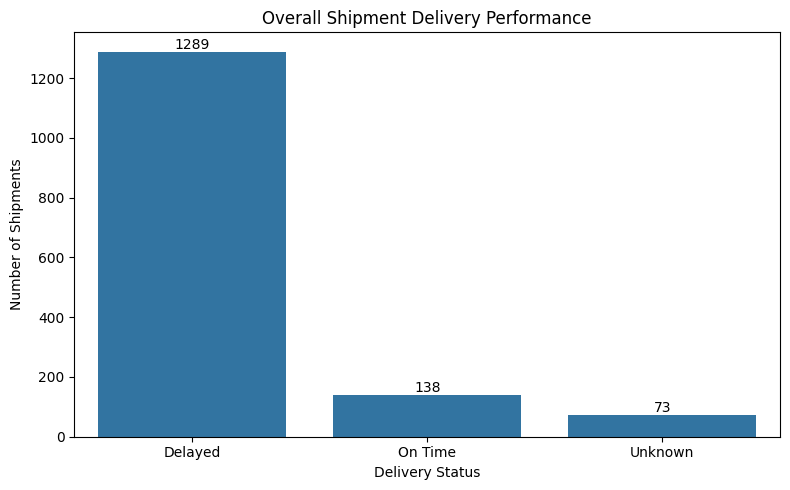

In [23]:
# Visualize overall delivery performance

status_counts = shipment_analysis["delivery_status"].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Overall Shipment Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")

# Display the count above each bar
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

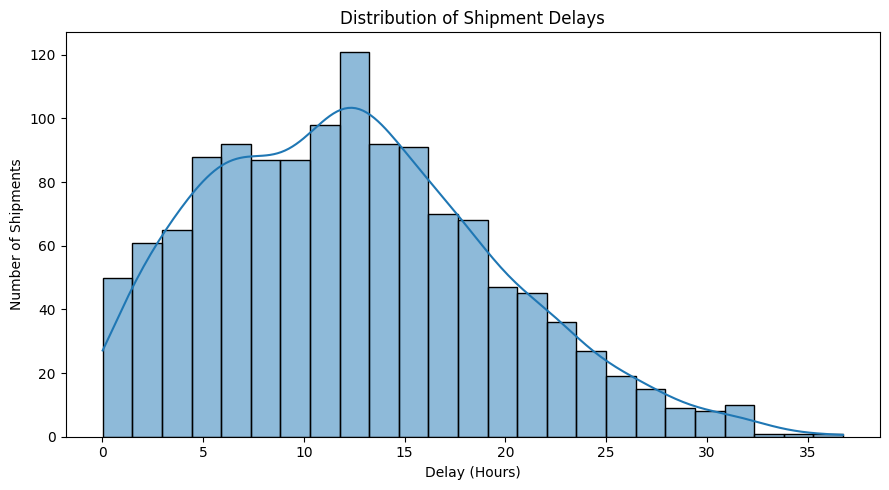

Number of delayed shipments analyzed: 1289
Average delay: 12.35 hours
Median delay: 11.98 hours
Maximum delay: 36.76 hours


In [24]:
# Analyze the distribution of shipment delays

delay_data = shipment_analysis.loc[
    shipment_analysis["delivery_status"] == "Delayed",
    "delay_hours"
].dropna()

plt.figure(figsize=(9, 5))

sns.histplot(
    delay_data,
    bins=25,
    kde=True
)

plt.title("Distribution of Shipment Delays")
plt.xlabel("Delay (Hours)")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

print("Number of delayed shipments analyzed:", len(delay_data))
print("Average delay:", round(delay_data.mean(), 2), "hours")
print("Median delay:", round(delay_data.median(), 2), "hours")
print("Maximum delay:", round(delay_data.max(), 2), "hours")

,route_id,origin,destination,total_shipments,delayed_shipments,average_delay_hours,delay_rate_percent
20,R021,Hyderabad,Chennai,36,33,11.99,91.67
27,R028,Mumbai,Chennai,35,31,10.74,88.57
47,R048,Coimbatore,Pune,32,31,14.69,96.88
14,R015,Hyderabad,Bengaluru,31,29,10.44,93.55
24,R025,Mumbai,Kochi,31,29,10.41,93.55
41,R042,Kochi,Chennai,30,29,10.66,96.67
10,R011,Bengaluru,Kochi,35,28,11.03,80.00
13,R014,Bengaluru,Chennai,29,28,12.83,96.55
53,R054,Pune,Kochi,30,28,12.22,93.33
32,R033,Delhi,Coimbatore,31,28,10.89,90.32


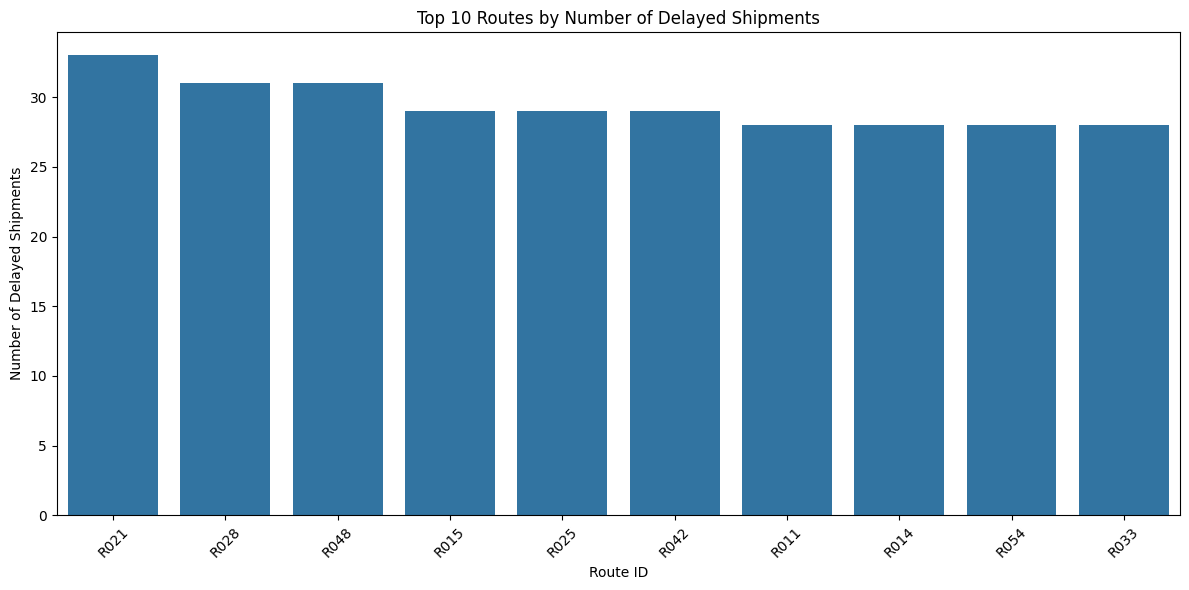

In [25]:
# Analyze delays by route

route_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby(["route_id", "origin", "destination"])
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean")
    )
    .reset_index()
)

route_analysis["delay_rate_percent"] = (
    route_analysis["delayed_shipments"]
    / route_analysis["total_shipments"] * 100
).round(2)

route_analysis["average_delay_hours"] = (
    route_analysis["average_delay_hours"].round(2)
)

# Show the 10 routes with the highest number of delayed shipments
top_delayed_routes = route_analysis.sort_values(
    by="delayed_shipments",
    ascending=False
).head(10)

display(top_delayed_routes)

# Visualize the results
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_delayed_routes,
    x="route_id",
    y="delayed_shipments"
)

plt.title("Top 10 Routes by Number of Delayed Shipments")
plt.xlabel("Route ID")
plt.ylabel("Number of Delayed Shipments")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

,carrier,total_shipments,delayed_shipments,average_delay_hours,average_transit_hours,delay_rate_percent
2,RapidHaul,270,233,9.09,23.04,86.30
1,BlueRoute Logistics,271,238,9.52,22.41,87.82
3,SwiftMove,279,243,9.90,22.40,87.10
4,TransWay,305,291,13.35,22.36,95.41
0,Apex Freight,302,284,13.43,21.72,94.04


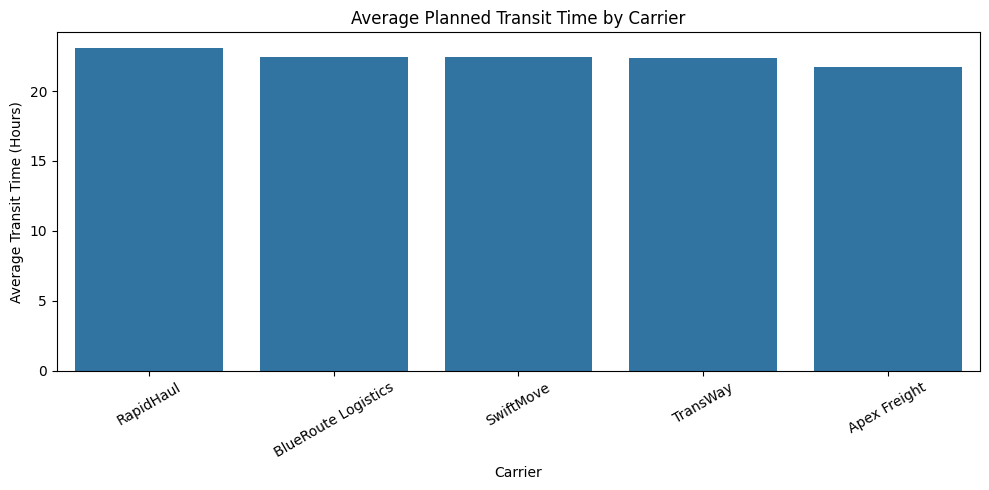

In [26]:
# Analyze delivery delays by carrier

carrier_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby("carrier")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean"),
        average_transit_hours=("transit_time_hours", "mean")
    )
    .reset_index()
)

carrier_analysis["delay_rate_percent"] = (
    carrier_analysis["delayed_shipments"]
    / carrier_analysis["total_shipments"] * 100
).round(2)

carrier_analysis["average_delay_hours"] = (
    carrier_analysis["average_delay_hours"].round(2)
)

carrier_analysis["average_transit_hours"] = (
    carrier_analysis["average_transit_hours"].round(2)
)

carrier_analysis = carrier_analysis.sort_values(
    by="average_transit_hours",
    ascending=False
)

display(carrier_analysis)

# Compare average planned transit time by carrier
plt.figure(figsize=(10, 5))

sns.barplot(
    data=carrier_analysis,
    x="carrier",
    y="average_transit_hours"
)

plt.title("Average Planned Transit Time by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Average Transit Time (Hours)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

,has_exception,total_shipments,delayed_shipments,average_delay_hours,average_exception_count,delay_rate_percent
0,False,1073,968,10.97,0.00,90.21
1,True,354,321,11.74,1.11,90.68


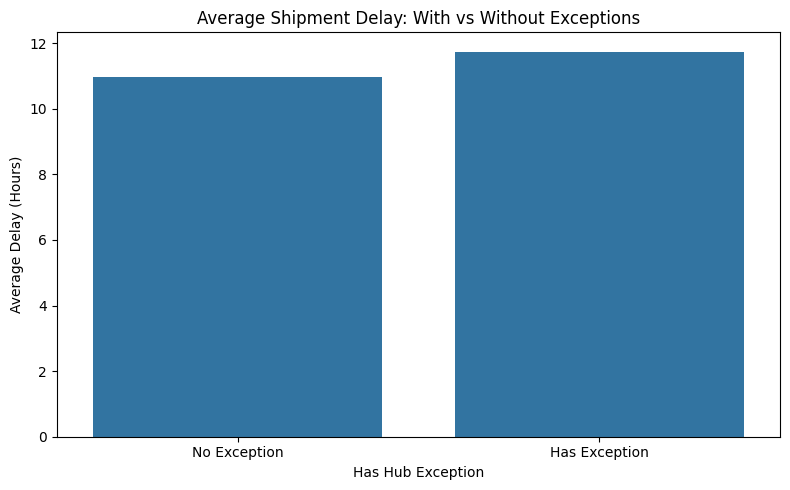

In [27]:
# Analyze the impact of hub exceptions on delivery delays

exception_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby("has_exception")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean"),
        average_exception_count=("exception_count", "mean")
    )
    .reset_index()
)

exception_analysis["delay_rate_percent"] = (
    exception_analysis["delayed_shipments"]
    / exception_analysis["total_shipments"] * 100
).round(2)

exception_analysis["average_delay_hours"] = (
    exception_analysis["average_delay_hours"].round(2)
)

exception_analysis["average_exception_count"] = (
    exception_analysis["average_exception_count"].round(2)
)

display(exception_analysis)

# Visualize average delay by exception status
plt.figure(figsize=(8, 5))

sns.barplot(
    data=exception_analysis,
    x="has_exception",
    y="average_delay_hours"
)

plt.title("Average Shipment Delay: With vs Without Exceptions")
plt.xlabel("Has Hub Exception")
plt.ylabel("Average Delay (Hours)")
plt.xticks([0, 1], ["No Exception", "Has Exception"])

plt.tight_layout()
plt.show()

,storm_flag,total_shipments,delayed_shipments,average_delay_hours,average_rain_mm,average_visibility_km,delay_rate_percent
0,False,1374,1236,10.79,7.62,7.90,89.96
1,True,53,53,20.73,11.88,7.32,100.00


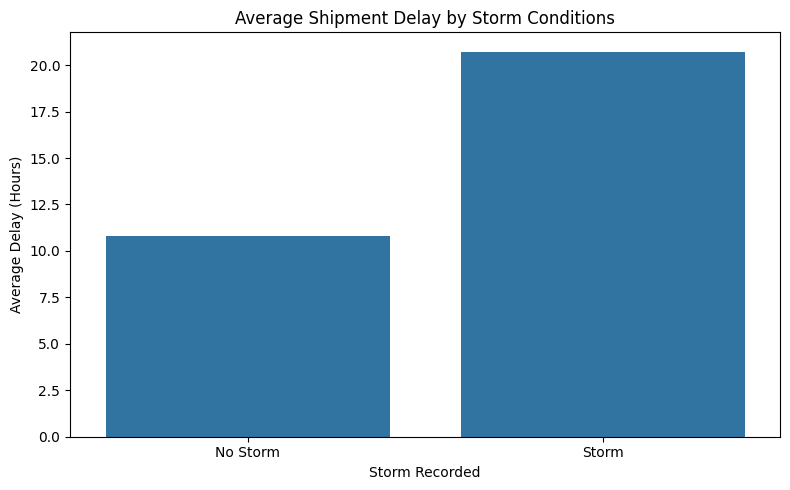

In [28]:
# Analyze the relationship between storms and shipment delays

weather_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby("storm_flag")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean"),
        average_rain_mm=("rain_mm", "mean"),
        average_visibility_km=("visibility_km", "mean")
    )
    .reset_index()
)

weather_analysis["delay_rate_percent"] = (
    weather_analysis["delayed_shipments"]
    / weather_analysis["total_shipments"] * 100
).round(2)

weather_analysis["average_delay_hours"] = (
    weather_analysis["average_delay_hours"].round(2)
)

weather_analysis["average_rain_mm"] = (
    weather_analysis["average_rain_mm"].round(2)
)

weather_analysis["average_visibility_km"] = (
    weather_analysis["average_visibility_km"].round(2)
)

display(weather_analysis)

# Visualize average delay by storm status
plt.figure(figsize=(8, 5))

sns.barplot(
    data=weather_analysis,
    x="storm_flag",
    y="average_delay_hours"
)

plt.title("Average Shipment Delay by Storm Conditions")
plt.xlabel("Storm Recorded")
plt.ylabel("Average Delay (Hours)")
plt.xticks([0, 1], ["No Storm", "Storm"])

plt.tight_layout()
plt.show()

,shipment_type,total_shipments,delayed_shipments,average_delay_hours,delay_rate_percent
4,Perishable,196,194,15.14,98.98
2,Fragile,187,185,15.50,98.93
1,Documents,187,168,10.24,89.84
3,Parcel,610,529,9.51,86.72
0,Bulk,247,213,9.48,86.23


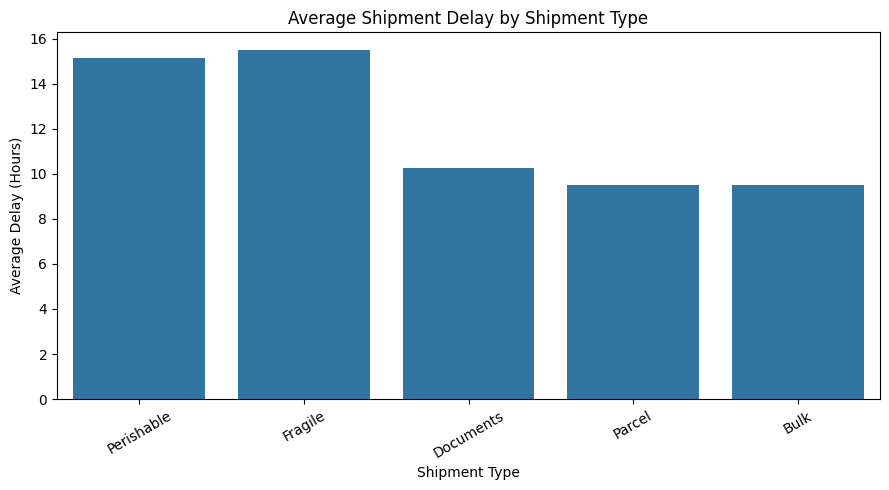

In [29]:
# Analyze delays by shipment type

shipment_type_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby("shipment_type")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean")
    )
    .reset_index()
)

shipment_type_analysis["delay_rate_percent"] = (
    shipment_type_analysis["delayed_shipments"]
    / shipment_type_analysis["total_shipments"] * 100
).round(2)

shipment_type_analysis["average_delay_hours"] = (
    shipment_type_analysis["average_delay_hours"].round(2)
)

shipment_type_analysis = shipment_type_analysis.sort_values(
    by="delay_rate_percent",
    ascending=False
)

display(shipment_type_analysis)

# Visualize average delay by shipment type
plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipment_type_analysis,
    x="shipment_type",
    y="average_delay_hours"
)

plt.title("Average Shipment Delay by Shipment Type")
plt.xlabel("Shipment Type")
plt.ylabel("Average Delay (Hours)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

,dispatch_period,total_shipments,delayed_shipments,average_delay_hours,delay_rate_percent
2,Morning,534,488,10.70,91.39
0,Afternoon,399,346,10.87,86.72
1,Evening,421,387,12.07,91.92
3,Night,73,68,10.84,93.15


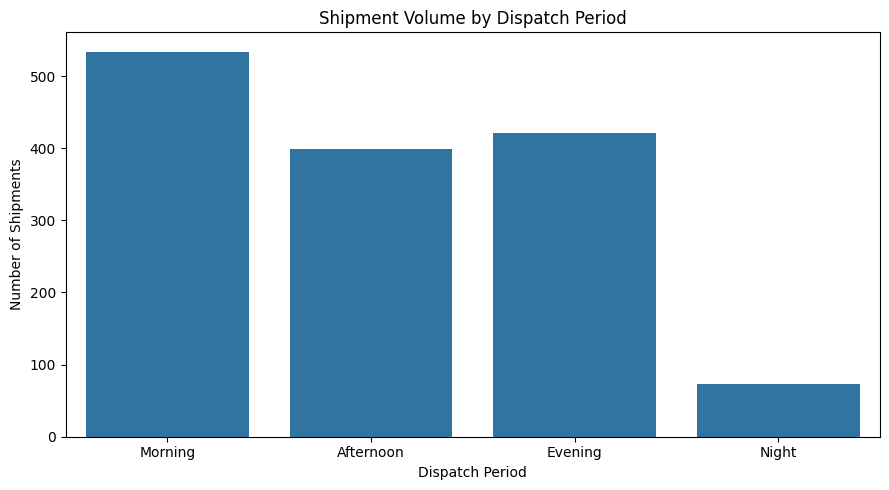

In [30]:
# Analyze shipment delays by dispatch period

dispatch_analysis = (
    shipment_analysis[
        shipment_analysis["delivery_status"] != "Unknown"
    ]
    .groupby("dispatch_period")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        ),
        average_delay_hours=("delay_hours", "mean")
    )
    .reset_index()
)

dispatch_analysis["delay_rate_percent"] = (
    dispatch_analysis["delayed_shipments"]
    / dispatch_analysis["total_shipments"] * 100
).round(2)

dispatch_analysis["average_delay_hours"] = (
    dispatch_analysis["average_delay_hours"].round(2)
)

# Keep dispatch periods in chronological order
period_order = ["Morning", "Afternoon", "Evening", "Night"]

dispatch_analysis["dispatch_period"] = pd.Categorical(
    dispatch_analysis["dispatch_period"],
    categories=period_order,
    ordered=True
)

dispatch_analysis = dispatch_analysis.sort_values("dispatch_period")

display(dispatch_analysis)

# Visualize shipment volume by dispatch period
plt.figure(figsize=(9, 5))

sns.barplot(
    data=dispatch_analysis,
    x="dispatch_period",
    y="total_shipments"
)

plt.title("Shipment Volume by Dispatch Period")
plt.xlabel("Dispatch Period")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

,rainfall_category,total_shipments,average_delay_hours,delayed_shipments,delay_rate_percent
0,No Rain,1,13.47,1,100.00
1,Light Rain,584,10.82,527,90.24
2,Moderate Rain,434,10.14,383,88.25
3,Heavy Rain,408,12.73,378,92.65


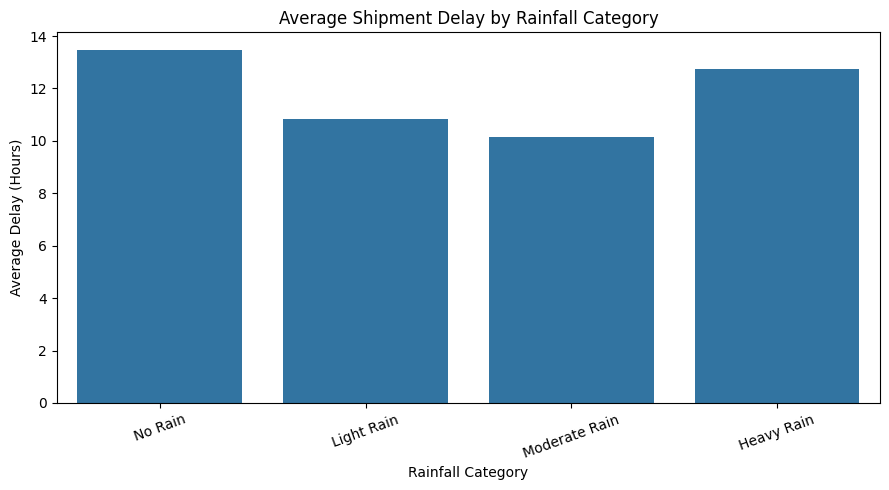

In [31]:
# Analyze the relationship between rainfall and shipment delays

rainfall_analysis = shipment_analysis[
    shipment_analysis["delivery_status"] != "Unknown"
].copy()

rainfall_analysis["rainfall_category"] = pd.cut(
    rainfall_analysis["rain_mm"],
    bins=[-0.01, 0, 5, 10, float("inf")],
    labels=["No Rain", "Light Rain", "Moderate Rain", "Heavy Rain"]
)

rain_summary = (
    rainfall_analysis
    .groupby("rainfall_category", observed=False)
    .agg(
        total_shipments=("shipment_id", "count"),
        average_delay_hours=("delay_hours", "mean"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

rain_summary["delay_rate_percent"] = (
    rain_summary["delayed_shipments"]
    / rain_summary["total_shipments"].replace(0, np.nan)
    * 100
).round(2)

rain_summary["average_delay_hours"] = (
    rain_summary["average_delay_hours"].round(2)
)

display(rain_summary)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=rain_summary,
    x="rainfall_category",
    y="average_delay_hours"
)

plt.title("Average Shipment Delay by Rainfall Category")
plt.xlabel("Rainfall Category")
plt.ylabel("Average Delay (Hours)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [32]:
# Encode categorical features for analysis and machine learning

categorical_columns = [
    "shipment_type",
    "carrier",
    "service_level",
    "dispatch_period",
    "dispatch_day"
]

encoding_data = shipment_analysis[
    categorical_columns
].copy()

encoded_features = pd.get_dummies(
    encoding_data,
    columns=categorical_columns,
    dtype=int
)

print("Original categorical columns:", len(categorical_columns))
print("Encoded feature count:", encoded_features.shape[1])
print("\nEncoded feature names:")
print(encoded_features.columns.tolist())

display(encoded_features.head())

Original categorical columns: 5
Encoded feature count: 24

Encoded feature names:
['shipment_type_Bulk', 'shipment_type_Documents', 'shipment_type_Fragile', 'shipment_type_Parcel', 'shipment_type_Perishable', 'carrier_Apex Freight', 'carrier_BlueRoute Logistics', 'carrier_RapidHaul', 'carrier_SwiftMove', 'carrier_TransWay', 'service_level_Economy', 'service_level_Express', 'service_level_Standard', 'dispatch_period_Afternoon', 'dispatch_period_Evening', 'dispatch_period_Morning', 'dispatch_period_Night', 'dispatch_day_Friday', 'dispatch_day_Monday', 'dispatch_day_Saturday', 'dispatch_day_Sunday', 'dispatch_day_Thursday', 'dispatch_day_Tuesday', 'dispatch_day_Wednesday']


,shipment_type_Bulk,shipment_type_Documents,shipment_type_Fragile,shipment_type_Parcel,shipment_type_Perishable,carrier_Apex Freight,carrier_BlueRoute Logistics,carrier_RapidHaul,carrier_SwiftMove,carrier_TransWay,...,dispatch_period_Evening,dispatch_period_Morning,dispatch_period_Night,dispatch_day_Friday,dispatch_day_Monday,dispatch_day_Saturday,dispatch_day_Sunday,dispatch_day_Thursday,dispatch_day_Tuesday,dispatch_day_Wednesday
0,0,0,0,1,0,0,1,0,0,0,...,1,0,0,0,0,1,0,0,0,0
1,0,0,0,1,0,1,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0
2,0,0,0,0,1,0,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,0,0,0,0,1,0,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,1,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


CORRELATION WITH SHIPMENT DELAY


,delay_hours
delay_hours,1.000000
rain_mm,0.145316
hub_count,0.126096
dispatch_hour,0.049424
exception_count,0.046937
transit_time_hours,-0.012270
distance_km,-0.040003
visibility_km,-0.050995


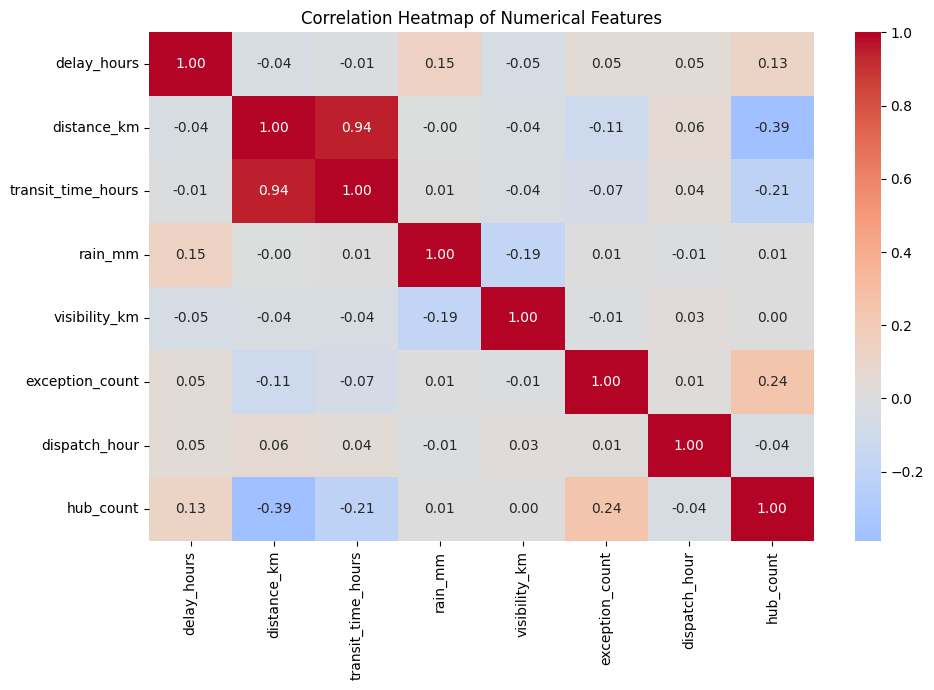

In [33]:
# Correlation analysis for numerical features

numerical_columns = [
    "delay_hours",
    "distance_km",
    "transit_time_hours",
    "rain_mm",
    "visibility_km",
    "exception_count",
    "dispatch_hour",
    "hub_count"
]

correlation_data = shipment_analysis[numerical_columns].copy()

correlation_matrix = correlation_data.corr()

print("CORRELATION WITH SHIPMENT DELAY")
display(
    correlation_matrix[["delay_hours"]]
    .sort_values(by="delay_hours", ascending=False)
)

# Visualize correlations among numerical features
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [34]:
# Prepare a feature-selection dataset

selected_columns = [
    "delay_hours",
    "distance_km",
    "transit_time_hours",
    "rain_mm",
    "visibility_km",
    "storm_flag",
    "exception_count",
    "has_exception",
    "hub_count",
    "shipment_type",
    "carrier",
    "service_level",
    "dispatch_period",
    "dispatch_day"
]

feature_selection_data = shipment_analysis[
    shipment_analysis["delivery_status"] != "Unknown"
][selected_columns].copy()

# Encode categorical features
feature_selection_data = pd.get_dummies(
    feature_selection_data,
    columns=[
        "shipment_type",
        "carrier",
        "service_level",
        "dispatch_period",
        "dispatch_day"
    ],
    dtype=int
)

# Separate target and predictors
X = feature_selection_data.drop(columns=["delay_hours"])
y = feature_selection_data["delay_hours"]

print("Feature-selection dataset shape:", feature_selection_data.shape)
print("Number of predictor features:", X.shape[1])
print("Target variable: delay_hours")
print("Missing values in predictors:", X.isna().sum().sum())
print("Missing values in target:", y.isna().sum())

display(X.head())

Feature-selection dataset shape: (1427, 33)
Number of predictor features: 32
Target variable: delay_hours
Missing values in predictors: 0
Missing values in target: 0


,distance_km,transit_time_hours,rain_mm,visibility_km,storm_flag,exception_count,has_exception,hub_count,shipment_type_Bulk,shipment_type_Documents,...,dispatch_period_Evening,dispatch_period_Morning,dispatch_period_Night,dispatch_day_Friday,dispatch_day_Monday,dispatch_day_Saturday,dispatch_day_Sunday,dispatch_day_Thursday,dispatch_day_Tuesday,dispatch_day_Wednesday
0,212,10.3,1.9,5.5,True,0,False,3,0,0,...,1,0,0,0,0,1,0,0,0,0
1,378,10.1,2.4,8.1,False,1,True,2,0,0,...,1,0,0,0,0,0,1,0,0,0
2,1536,26.1,5.5,5.3,False,0,False,1,0,0,...,1,0,0,0,1,0,0,0,0,0
3,1557,29.7,0.6,6.6,False,0,False,3,0,0,...,1,0,0,0,0,0,0,0,1,0
4,342,10.3,6.2,6.8,False,0,False,2,0,0,...,0,0,0,0,1,0,0,0,0,0


In [35]:
# Identify highly correlated numerical predictor features

numerical_features = [
    "distance_km",
    "transit_time_hours",
    "rain_mm",
    "visibility_km",
    "exception_count",
    "hub_count"
]

feature_corr = X[numerical_features].corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] >= 0.80
].sort_values(
    by="Absolute Correlation",
    ascending=False
)

print("Highly correlated feature pairs (absolute correlation >= 0.80):")

if high_corr_pairs.empty:
    print("No highly correlated numerical feature pairs found.")
else:
    display(high_corr_pairs)

Highly correlated feature pairs (absolute correlation >= 0.80):


,Feature 1,Feature 2,Absolute Correlation
0,distance_km,transit_time_hours,0.943464


In [36]:
# Finalize selected features by removing the redundant distance feature

X_selected = X.drop(columns=["distance_km"]).copy()

print("Original predictor count:", X.shape[1])
print("Selected predictor count:", X_selected.shape[1])
print("Removed feature: distance_km")
print("Retained feature: transit_time_hours")
print("Missing values in selected features:", X_selected.isna().sum().sum())

print("\nSelected feature names:")
print(X_selected.columns.tolist())

display(X_selected.head())

Original predictor count: 32
Selected predictor count: 31
Removed feature: distance_km
Retained feature: transit_time_hours
Missing values in selected features: 0

Selected feature names:
['transit_time_hours', 'rain_mm', 'visibility_km', 'storm_flag', 'exception_count', 'has_exception', 'hub_count', 'shipment_type_Bulk', 'shipment_type_Documents', 'shipment_type_Fragile', 'shipment_type_Parcel', 'shipment_type_Perishable', 'carrier_Apex Freight', 'carrier_BlueRoute Logistics', 'carrier_RapidHaul', 'carrier_SwiftMove', 'carrier_TransWay', 'service_level_Economy', 'service_level_Express', 'service_level_Standard', 'dispatch_period_Afternoon', 'dispatch_period_Evening', 'dispatch_period_Morning', 'dispatch_period_Night', 'dispatch_day_Friday', 'dispatch_day_Monday', 'dispatch_day_Saturday', 'dispatch_day_Sunday', 'dispatch_day_Thursday', 'dispatch_day_Tuesday', 'dispatch_day_Wednesday']


,transit_time_hours,rain_mm,visibility_km,storm_flag,exception_count,has_exception,hub_count,shipment_type_Bulk,shipment_type_Documents,shipment_type_Fragile,...,dispatch_period_Evening,dispatch_period_Morning,dispatch_period_Night,dispatch_day_Friday,dispatch_day_Monday,dispatch_day_Saturday,dispatch_day_Sunday,dispatch_day_Thursday,dispatch_day_Tuesday,dispatch_day_Wednesday
0,10.3,1.9,5.5,True,0,False,3,0,0,0,...,1,0,0,0,0,1,0,0,0,0
1,10.1,2.4,8.1,False,1,True,2,0,0,0,...,1,0,0,0,0,0,1,0,0,0
2,26.1,5.5,5.3,False,0,False,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,29.7,0.6,6.6,False,0,False,3,0,0,0,...,1,0,0,0,0,0,0,0,1,0
4,10.3,6.2,6.8,False,0,False,2,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [37]:
# Final validation of Round 2 EDA and feature engineering

print("===== ROUND 2 FINAL VALIDATION =====")

print("\n1. Cleaned shipment data")
print("Total shipment records:", len(shipment_analysis))
print("Duplicate shipment IDs:", shipment_analysis["shipment_id"].duplicated().sum())

print("\n2. Delivery status")
print(shipment_analysis["delivery_status"].value_counts())

print("\n3. Engineered features")
engineered_columns = [
    "delay_hours",
    "delivery_status",
    "transit_time_hours",
    "rain_mm",
    "visibility_km",
    "storm_flag",
    "exception_count",
    "has_exception",
    "dispatch_hour",
    "dispatch_day",
    "dispatch_period",
    "hub_count"
]

print("Engineered columns available:",
      all(col in shipment_analysis.columns for col in engineered_columns))

print("\n4. Feature selection")
print("Selected predictor count:", X_selected.shape[1])
print("Target variable:", y.name)
print("Missing predictor values:", X_selected.isna().sum().sum())
print("Missing target values:", y.isna().sum())

print("\n5. Business question analysis objects")
analysis_objects = {
    "Route analysis": "route_analysis",
    "Carrier analysis": "carrier_analysis",
    "Exception analysis": "exception_analysis",
    "Weather analysis": "weather_analysis",
    "Shipment type analysis": "shipment_type_analysis",
    "Dispatch analysis": "dispatch_analysis",
    "Rainfall analysis": "rain_summary"
}

for label, object_name in analysis_objects.items():
    print(f"{label}: {'Available' if object_name in globals() else 'Missing'}")

print("\n===== VALIDATION COMPLETE =====")

===== ROUND 2 FINAL VALIDATION =====

1. Cleaned shipment data
Total shipment records: 1500
Duplicate shipment IDs: 0

2. Delivery status
delivery_status
Delayed    1289
On Time     138
Unknown      73
Name: count, dtype: int64

3. Engineered features
Engineered columns available: True

4. Feature selection
Selected predictor count: 31
Target variable: delay_hours
Missing predictor values: 0
Missing target values: 0

5. Business question analysis objects
Route analysis: Available
Carrier analysis: Available
Exception analysis: Available
Weather analysis: Available
Shipment type analysis: Available
Dispatch analysis: Available
Rainfall analysis: Available

===== VALIDATION COMPLETE =====


**6.Model Training**

In [38]:
# Step 6.1: Prepare the target for delay classification

ml_data = shipment_analysis[
    shipment_analysis["delivery_status"].isin(["Delayed", "On Time"])
].copy()

ml_data["is_delayed"] = (
    ml_data["delivery_status"] == "Delayed"
).astype(int)

print("Total labeled shipments:", len(ml_data))
print("\nTarget distribution:")
print(
    ml_data["is_delayed"]
    .value_counts()
    .rename(index={0: "On Time", 1: "Delayed"})
)

print("\nTarget percentages:")
print(
    (
        ml_data["is_delayed"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
)

print("\nTarget variable: is_delayed")

Total labeled shipments: 1427

Target distribution:
is_delayed
Delayed    1289
On Time     138
Name: count, dtype: int64

Target percentages:
is_delayed
1    90.33
0     9.67
Name: proportion, dtype: float64

Target variable: is_delayed


In [39]:
# Step 6.2: Prepare classification features and split the data

from sklearn.model_selection import train_test_split

# Remove target and fields that would reveal the delivery outcome
columns_to_exclude = [
    "shipment_id",
    "route_id",
    "carrier_id",
    "origin",
    "destination",
    "dispatch_date",
    "promised_delivery_date",
    "actual_delivery_date",
    "delay_hours",
    "delivery_status",
    "distance_km",       # Removed due to high correlation with transit time
    "has_exception"      # Redundant with exception_count > 0
]

X_classification = ml_data.drop(
    columns=columns_to_exclude + ["is_delayed"],
    errors="ignore"
).copy()

# Encode remaining categorical variables
X_classification = pd.get_dummies(
    X_classification,
    columns=X_classification.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist(),
    dtype=int
)

y_classification = ml_data["is_delayed"]

# Stratified split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().rename(index={0: "On Time", 1: "Delayed"}))

print("\nTesting target distribution:")
print(y_test.value_counts().rename(index={0: "On Time", 1: "Delayed"}))

print("\nMissing values in training features:", X_train.isna().sum().sum())
print("Missing values in testing features:", X_test.isna().sum().sum())

Training features: (1141, 68)
Testing features: (286, 68)

Training target distribution:
is_delayed
Delayed    1031
On Time     110
Name: count, dtype: int64

Testing target distribution:
is_delayed
Delayed    258
On Time     28
Name: count, dtype: int64

Missing values in training features: 0
Missing values in testing features: 0


In [40]:
# Step 6.3: Train the Random Forest classification model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")
print("Training samples:", X_train.shape[0])
print("Features used:", X_train.shape[1])
print("Number of trees:", rf_model.n_estimators)

Random Forest model trained successfully!
Training samples: 1141
Features used: 68
Number of trees: 200


In [41]:
# Step 6.4: Predict and evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict on the unseen test set
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("===== RANDOM FOREST MODEL PERFORMANCE =====")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["On Time", "Delayed"],
        zero_division=0
    )
)

print("===== CONFUSION MATRIX =====")
print("Rows = Actual | Columns = Predicted")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

===== RANDOM FOREST MODEL PERFORMANCE =====
Accuracy:  0.8566 (85.66%)
Precision: 0.9125
Recall:    0.9302
F1-score:  0.9213

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

     On Time       0.22      0.18      0.20        28
     Delayed       0.91      0.93      0.92       258

    accuracy                           0.86       286
   macro avg       0.56      0.55      0.56       286
weighted avg       0.84      0.86      0.85       286

===== CONFUSION MATRIX =====
Rows = Actual | Columns = Predicted
[[  5  23]
 [ 18 240]]


TOP 15 IMPORTANT FEATURES


,Feature,Importance
1,rain_mm,0.125797
2,visibility_km,0.087511
0,transit_time_hours,0.072487
11,shipment_type_Perishable,0.070510
9,shipment_type_Fragile,0.062145
5,dispatch_hour,0.060937
53,carrier_TransWay,0.045568
10,shipment_type_Parcel,0.032599
6,hub_count,0.032554
64,dispatch_period_Afternoon,0.022719


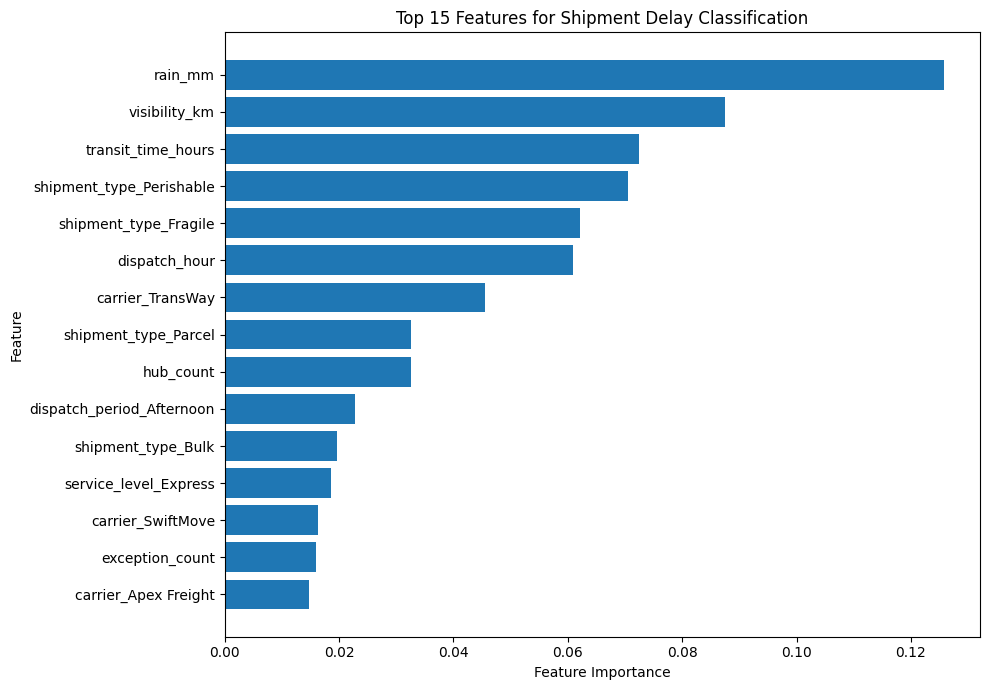

In [42]:
# Step 6.5: Identify the most important features

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15))

# Visualize the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features for Shipment Delay Classification")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [43]:
# Step 6.6: Train a second model with stronger minority-class weighting

rf_model_balanced = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight={0: 3, 1: 1},
    random_state=42,
    n_jobs=-1
)

rf_model_balanced.fit(X_train, y_train)

# Predict on the same held-out test set
y_pred_balanced = rf_model_balanced.predict(X_test)

print("Second Random Forest model trained.")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_balanced,
        labels=[0, 1],
        target_names=["On Time", "Delayed"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced, labels=[0, 1]))

Second Random Forest model trained.

Classification Report:
              precision    recall  f1-score   support

     On Time       1.00      0.04      0.07        28
     Delayed       0.91      1.00      0.95       258

    accuracy                           0.91       286
   macro avg       0.95      0.52      0.51       286
weighted avg       0.91      0.91      0.86       286

Confusion Matrix:
[[  1  27]
 [  0 258]]


In [44]:
# Step 6.7: Compare both Random Forest models

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score
)

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest - Balanced",
        "Accuracy": accuracy_score(y_test, y_pred),
        "On-Time Precision": precision_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "On-Time Recall": recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "On-Time F1": f1_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    },
    {
        "Model": "Random Forest - On-Time Weighted",
        "Accuracy": accuracy_score(y_test, y_pred_balanced),
        "On-Time Precision": precision_score(
            y_test, y_pred_balanced, pos_label=0, zero_division=0
        ),
        "On-Time Recall": recall_score(
            y_test, y_pred_balanced, pos_label=0, zero_division=0
        ),
        "On-Time F1": f1_score(
            y_test, y_pred_balanced, pos_label=0, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred_balanced, average="macro", zero_division=0
        )
    }
])

display(model_comparison.round(4))

,Model,Accuracy,On-Time Precision,On-Time Recall,On-Time F1,Macro F1
0,Random Forest - Balanced,0.8566,0.2174,0.1786,0.1961,0.5587
1,Random Forest - On-Time Weighted,0.9056,1.0000,0.0357,0.0690,0.5096


In [45]:
# Step 6.8: Train and evaluate balanced Logistic Regression

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("===== LOGISTIC REGRESSION RESULTS =====")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=[0, 1],
        target_names=["On Time", "Delayed"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

===== LOGISTIC REGRESSION RESULTS =====

Classification Report:
              precision    recall  f1-score   support

     On Time       0.17      0.64      0.26        28
     Delayed       0.94      0.65      0.77       258

    accuracy                           0.65       286
   macro avg       0.55      0.65      0.52       286
weighted avg       0.87      0.65      0.72       286

Confusion Matrix:
[[ 18  10]
 [ 91 167]]


In [46]:
# Step 6.9: Compare all three models

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

predictions = {
    "Random Forest - First": y_pred,
    "Random Forest - On-Time Weighted": y_pred_balanced,
    "Logistic Regression": y_pred_lr
}

comparison_results = []

for model_name, predictions_for_model in predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions_for_model),
        "On-Time Recall": recall_score(
            y_test, predictions_for_model, pos_label=0, zero_division=0
        ),
        "On-Time F1": f1_score(
            y_test, predictions_for_model, pos_label=0, zero_division=0
        ),
        "Delayed Recall": recall_score(
            y_test, predictions_for_model, pos_label=1, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions_for_model, average="macro", zero_division=0
        )
    })

final_model_comparison = pd.DataFrame(comparison_results)

display(
    final_model_comparison
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

,Model,Accuracy,On-Time Recall,On-Time F1,Delayed Recall,Macro F1
0,Random Forest - First,0.8566,0.1786,0.1961,0.9302,0.5587
2,Logistic Regression,0.6469,0.6429,0.2628,0.6473,0.5153
1,Random Forest - On-Time Weighted,0.9056,0.0357,0.0690,1.0000,0.5096


In [47]:
# Step 6.10: Save the model and evaluation artifacts

import joblib
import os

os.makedirs("round2_outputs", exist_ok=True)

# Save the baseline model
joblib.dump(
    rf_model,
    "round2_outputs/shipment_delay_random_forest.pkl"
)

# Save model comparison results
final_model_comparison.to_csv(
    "round2_outputs/model_comparison.csv",
    index=False
)

# Save selected feature names
pd.Series(X_train.columns, name="feature").to_csv(
    "round2_outputs/selected_features.csv",
    index=False
)

print("Saved files:")
print("- round2_outputs/shipment_delay_random_forest.pkl")
print("- round2_outputs/model_comparison.csv")
print("- round2_outputs/selected_features.csv")

print("\nSelected model: First Random Forest")
print(f"Test accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Macro F1-score: {f1_score(y_test, y_pred, average='macro'):.4f}")

Saved files:
- round2_outputs/shipment_delay_random_forest.pkl
- round2_outputs/model_comparison.csv
- round2_outputs/selected_features.csv

Selected model: First Random Forest
Test accuracy: 85.66%
Macro F1-score: 0.5587


### Round 2 – Feature Engineering & Machine Learning

**Selected Features:** Transit time, rainfall, visibility, storm flag, exception count, hub count, shipment type, carrier, service level, dispatch hour, dispatch period and dispatch day.

**Target Variable:** `is_delayed` (Delayed = 1, On Time = 0).

**ML Algorithm Used:** Random Forest Classifier.

**Justification:** Random Forest can capture nonlinear relationships between operational and weather-related features. Class imbalance was considered during model experimentation.

**Model Performance:**
- Accuracy: 85.66%
- Macro F1-score: 0.5587
- Delayed-class precision: 0.9125
- Delayed-class recall: 0.9302
- On-time recall: 0.1786

**Key Limitation:** The model performs well at identifying delayed shipments but has low recall for on-time shipments.

In [48]:
import os

for file in os.listdir("round2_outputs"):
    print(file)

selected_features.csv
model_comparison.csv
shipment_delay_random_forest.pkl


In [49]:
import shutil
import os

zip_path = shutil.make_archive(
    "Round2_Shipment_Delay_Outputs",
    "zip",
    root_dir="round2_outputs"
)

print("ZIP created successfully!")
print("File:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

ZIP created successfully!
File: /content/Round2_Shipment_Delay_Outputs.zip
Size: 660.57 KB


**Round 3**

In [50]:
#  Export cleaned shipment data for Excel

excel_data = shipment_analysis.copy()

excel_data.to_csv(
    "Round3_Cleaned_Shipment_Data.csv",
    index=False
)

print("Export completed successfully!")
print("Rows:", excel_data.shape[0])
print("Columns:", excel_data.shape[1])
print("File: Round3_Cleaned_Shipment_Data.csv")

Export completed successfully!
Rows: 1500
Columns: 25
File: Round3_Cleaned_Shipment_Data.csv
